
# P15 — Projeto Integrador: Previsão de Churn

**Especialização em Inteligência Artificial — UNIFAP**

## Objetivo

Desenvolver um pipeline end-to-end de Engenharia de Dados
e Machine Learning, integrando duas fontes de dados,
armazenamento PostgreSQL, ETL Python, engenharia de
features, treinamento e avaliação de modelos.

**Problema:** classificação de clientes com possível
churn, definido neste experimento como recência de
compra superior a 90 dias.

**Natureza dos dados:** sintéticos, utilizados para
demonstração acadêmica.



## 1. Arquitetura do projeto

Fluxo implementado:

1. Fonte 1: histórico de vendas (`dados/vendas.csv`);
2. Fonte 2: cadastro de clientes (`dados/clientes.csv`);
3. PostgreSQL: banco `p15_churn_db`;
4. ETL: extração, validação e carga com Python;
5. Integração por `cliente_id`;
6. Engenharia de features;
7. Treinamento e validação cruzada;
8. Comparação de modelos e geração de artefatos.

O treinamento foi executado em Docker para garantir
um ambiente Linux reproduzível.


In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path.cwd()
OUTPUT = BASE / "output"

print("Diretorio do projeto:", BASE)


Diretorio do projeto: /app



## 2. Fontes de dados

As duas fontes são integradas pelo identificador
`cliente_id`.

A fonte de vendas contém informações transacionais.
A fonte de clientes contém informações cadastrais
e características comerciais.

Os dados são sintéticos e não contêm informações
reais de clientes.


In [2]:

vendas = pd.read_csv(BASE / "dados" / "vendas.csv")
clientes = pd.read_csv(BASE / "dados" / "clientes.csv")

print("Vendas:", vendas.shape)
print("Clientes:", clientes.shape)

display(vendas.head())
display(clientes.head())


Vendas: (787, 10)
Clientes: (197, 6)


,id_venda,cliente_id,data_cadastro,ultima_compra,cidade,segmento,produto_id,idade,quantidade,valor
0,1,18,2024-04-22,2026-06-05,Manaus,Intermediario,Headset,22.0,4,516.18
1,2,106,2023-10-20,2026-05-21,Santarem,Premium,Monitor,47.0,1,2279.41
2,3,101,2025-04-28,2026-08-29,Boa Vista,Premium,Monitor,41.0,5,2244.90
3,4,91,2025-09-07,2026-09-15,Manaus,Premium,Notebook,67.0,5,3176.74
4,5,34,2024-05-07,2026-05-28,Belem,Basico,Headset,43.0,5,3903.00


,cliente_id,canal_aquisicao,tipo_contrato,preferencia_contato,aceita_marketing,possui_programa_fidelidade
0,1,Indicacao,Anual,Email,1,1
1,2,Loja fisica,Mensal,WhatsApp,0,1
2,3,Indicacao,Mensal,WhatsApp,1,0
3,4,Loja fisica,Trimestral,Email,0,0
4,5,Online,Anual,WhatsApp,0,0



## 3. Validação das fontes

São verificadas a quantidade de registros,
a duplicidade de identificadores e a correspondência
entre as duas fontes.


In [3]:

print("Vendas duplicadas por id_venda:",
      vendas["id_venda"].duplicated().sum())

print("Clientes duplicados por cliente_id:",
      clientes["cliente_id"].duplicated().sum())

ids_sem_cadastro = (
    set(vendas["cliente_id"])
    - set(clientes["cliente_id"])
)

print("Clientes referenciados sem cadastro:",
      len(ids_sem_cadastro))


Vendas duplicadas por id_venda: 0
Clientes duplicados por cliente_id: 0
Clientes referenciados sem cadastro: 0



## 4. ETL e armazenamento PostgreSQL

O script `etl_p15.py` executa a leitura e validação
das duas fontes e a carga no PostgreSQL.

O banco `p15_churn_db` contém as tabelas `clientes`
e `vendas`.

Na execução validada do projeto, foram registrados:

- 197 clientes;
- 787 vendas;
- 787 vendas associadas a clientes cadastrados.

A reprodução da carga depende de uma instância
PostgreSQL configurada conforme o README.


In [4]:

from pathlib import Path

etl = BASE / "etl_p15.py"
print("Script ETL disponível:", etl.exists())

print("Arquivos de origem:")
print((BASE / "dados" / "clientes.csv").exists())
print((BASE / "dados" / "vendas.csv").exists())


Script ETL disponível: True
Arquivos de origem:
True
True



## 5. Engenharia de features

O script `features_p15.py` consulta o PostgreSQL,
integra as tabelas e agrega o histórico de vendas
por cliente.

São produzidas variáveis de frequência, valor,
diversidade de produtos, características temporais
e atributos cadastrais.

O alvo `churn` foi definido como recência superior
a 90 dias na data de referência de 08/10/2026.


In [5]:

df = pd.read_csv(
    OUTPUT / "clientes_features_p15.csv"
)

print("Clientes:", len(df))
print("Colunas totais:", len(df.columns))
print("Valores ausentes:", df.isna().sum().sum())
print("IDs duplicados:",
      df["cliente_id"].duplicated().sum())

display(df.head())


Clientes: 197
Colunas totais: 32
Valores ausentes: 0
IDs duplicados: 0


,cliente_id,data_cadastro,ultima_compra,cidade,segmento,idade,canal_aquisicao,tipo_contrato,preferencia_contato,aceita_marketing,...,mes_cadastro,ano_cadastro,media_mensal_compras,valor_por_produto,amplitude_compras,produtos_por_compra,diversidade_por_compra,coef_variacao_valor,faixa_etaria,churn
0,1,2024-01-04,2026-09-04,Boa Vista,Premium,20.5,Indicacao,Anual,Email,1,...,1,2024,0.181190,1293.310833,6634.01,2.000000,0.666667,1.091848,ate_25,0
1,2,2023-11-25,2026-07-04,Desconhecida,Basico,33.0,Loja fisica,Mensal,WhatsApp,0,...,11,2023,0.116183,1043.418333,4368.76,3.000000,0.500000,0.603297,26_40,1
2,3,2023-10-29,2026-07-27,Macapa,Premium,65.0,Indicacao,Mensal,WhatsApp,1,...,10,2023,0.141581,1586.055833,4949.31,2.400000,0.600000,0.552765,acima_60,0
3,4,2025-01-27,2026-07-12,Macapa,Intermediario,22.0,Loja fisica,Trimestral,Email,0,...,1,2025,0.147528,3385.978000,6209.00,1.666667,1.000000,0.596317,ate_25,0
4,5,2023-09-28,2026-09-26,Macapa,Intermediario,42.0,Online,Anual,WhatsApp,0,...,9,2023,0.137613,2203.997143,19347.91,2.800000,0.600000,1.282941,41_60,0



## 6. Análise exploratória — distribuição do alvo

A base apresenta desbalanceamento entre clientes
classificados com churn e sem churn.

Por isso, a avaliação não deve depender apenas
da acurácia. São utilizadas precisão, recall
e F1-score.


churn
0    170
1     27
Name: count, dtype: int64


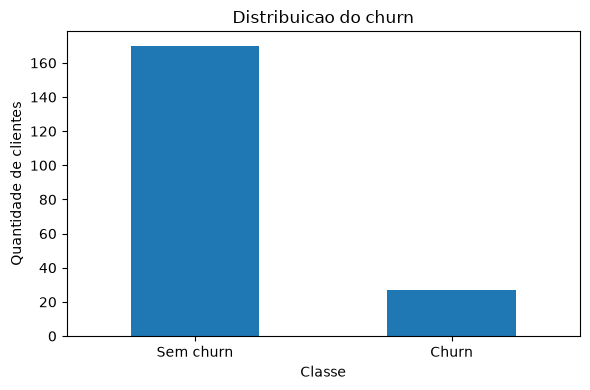

In [6]:

distribuicao = df["churn"].value_counts().sort_index()

print(distribuicao)

ax = distribuicao.plot(
    kind="bar",
    figsize=(6, 4),
    title="Distribuicao do churn"
)

ax.set_xlabel("Classe")
ax.set_ylabel("Quantidade de clientes")
ax.set_xticklabels(["Sem churn", "Churn"], rotation=0)

plt.tight_layout()
plt.show()



## 7. Análise exploratória — comportamento de compra

São examinadas as distribuições de compras e
valores acumulados por cliente, sem interpretar
associações sintéticas como relações causais reais.


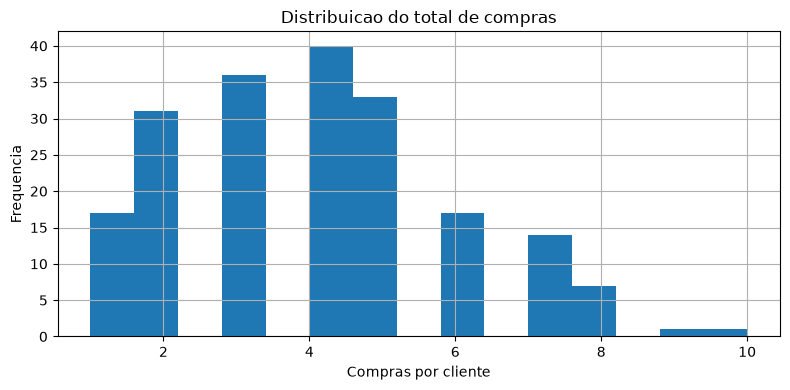

In [7]:

fig, ax = plt.subplots(figsize=(8, 4))

df["total_compras"].hist(
    bins=15,
    ax=ax
)

ax.set_title("Distribuicao do total de compras")
ax.set_xlabel("Compras por cliente")
ax.set_ylabel("Frequencia")

plt.tight_layout()
plt.show()


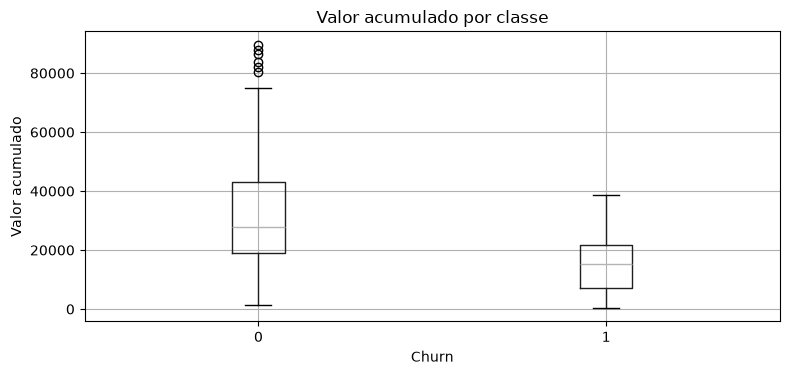

In [8]:

fig, ax = plt.subplots(figsize=(8, 4))

df.boxplot(
    column="valor_acumulado",
    by="churn",
    ax=ax
)

plt.suptitle("")
ax.set_title("Valor acumulado por classe")
ax.set_xlabel("Churn")
ax.set_ylabel("Valor acumulado")

plt.tight_layout()
plt.show()



## 8. Preparação para Machine Learning

O treinamento utiliza 27 features de entrada.

Foram excluídos identificadores, datas brutas
e a variável `recencia_dias`, que define diretamente
o alvo sintético.

O pré-processamento é realizado dentro do Pipeline
do scikit-learn, com imputação, padronização
e One-Hot Encoding.

A divisão é estratificada: 80% para treinamento
e 20% para teste.


In [9]:

X_train = pd.read_csv(OUTPUT / "X_train_p15.csv")
X_test = pd.read_csv(OUTPUT / "X_test_p15.csv")
y_train = pd.read_csv(OUTPUT / "y_train_p15.csv")
y_test = pd.read_csv(OUTPUT / "y_test_p15.csv")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (157, 27)
X_test: (40, 27)
y_train: (157, 1)
y_test: (40, 1)



## 9. Modelos avaliados

Foram comparados três classificadores:

- Regressão Logística;
- Random Forest;
- Gradient Boosting.

A seleção do modelo foi baseada no F1 médio
da validação cruzada estratificada com cinco folds,
calculada apenas no conjunto de treinamento.


In [10]:

comparacao = pd.read_csv(
    OUTPUT / "comparacao_modelos_p15.csv"
)

display(comparacao)


,modelo,f1_cv_medio,f1_cv_desvio,acuracia_teste,precisao_teste,recall_teste,f1_teste
0,Random Forest,0.249658,0.162514,0.800,0.200000,0.2,0.200000
1,Gradient Boosting,0.246667,0.208273,0.825,0.250000,0.2,0.222222
2,Regressao Logistica,0.211364,0.122727,0.800,0.333333,0.6,0.428571


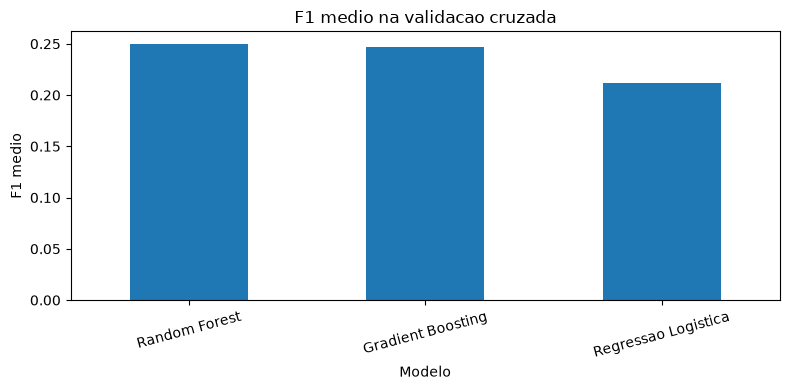

In [11]:

ax = comparacao.plot(
    x="modelo",
    y="f1_cv_medio",
    kind="bar",
    legend=False,
    figsize=(8, 4),
    title="F1 medio na validacao cruzada"
)

ax.set_xlabel("Modelo")
ax.set_ylabel("F1 medio")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



## 10. Seleção e resultados

O Random Forest apresentou o maior F1 médio
na validação cruzada e foi selecionado pelo
critério definido antes da avaliação no teste.

Resultados observados:

| Modelo | F1 CV médio | Acurácia teste | F1 teste |
|---|---:|---:|---:|
| Random Forest | 0,2497 | 0,8000 | 0,2000 |
| Gradient Boosting | 0,2467 | 0,8250 | 0,2222 |
| Regressão Logística | 0,2114 | 0,8000 | 0,4286 |

Embora a Regressão Logística tenha apresentado
maior F1 no teste, esse resultado não foi utilizado
para escolher o modelo, evitando seleção orientada
pelo conjunto reservado para avaliação.


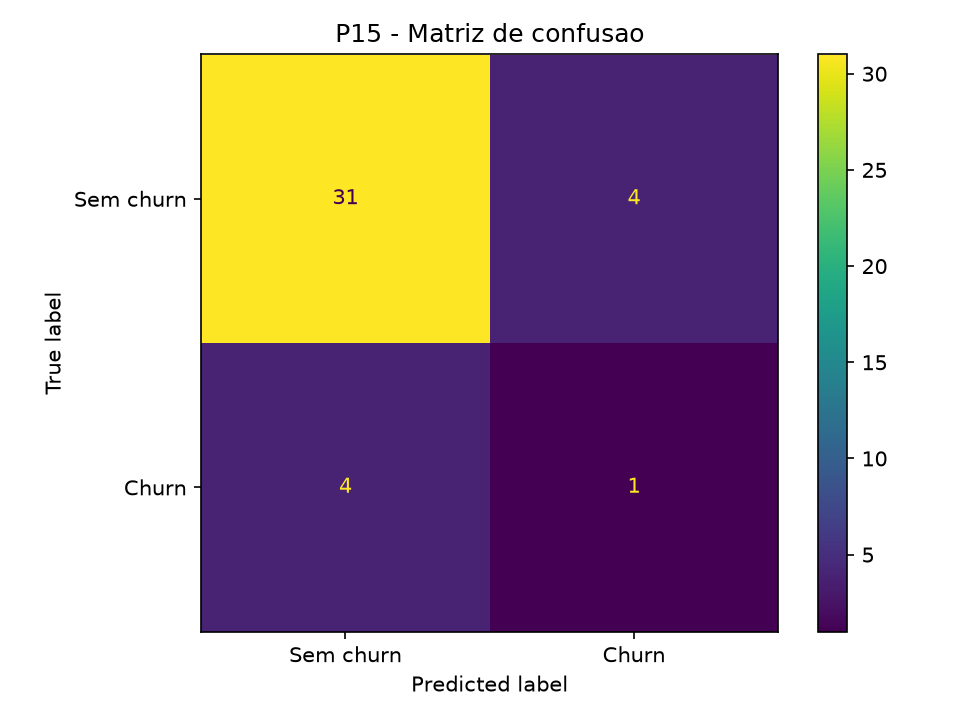

In [12]:

from IPython.display import Image, display

display(Image(
    filename=str(OUTPUT / "matriz_confusao_p15.png")
))



## 11. Interpretação da avaliação

O Random Forest obteve acurácia de 80% no teste,
mas apresentou recall de apenas 20% para churn.

Isso significa que identificou somente um dos
cinco clientes classificados com churn no conjunto
de teste.

A diferença entre acurácia e recall demonstra
a importância de avaliar métricas adequadas
para classes desbalanceadas.

O resultado não deve ser interpretado como
desempenho comprovado em produção.



## 12. Artefatos do modelo

O arquivo `modelo_churn_p15.pkl` contém o Pipeline
completo, incluindo pré-processamento e classificador.

O projeto também disponibiliza métricas em CSV,
gráficos, relatório de classificação, partições
de treinamento e teste e metadados do experimento.

A execução deve ocorrer em ambiente com dependências
compatíveis, preferencialmente utilizando Docker.


In [13]:

artefatos = [
    "modelo_churn_p15.pkl",
    "comparacao_modelos_p15.csv",
    "matriz_confusao_p15.png",
    "metadados_p15.json",
    "relatorio_classificacao_p15.txt"
]

for nome in artefatos:
    print(nome, (OUTPUT / nome).exists())


modelo_churn_p15.pkl True
comparacao_modelos_p15.csv True
matriz_confusao_p15.png True
metadados_p15.json True
relatorio_classificacao_p15.txt True



## 13. Limitações e trabalhos futuros

Este estudo utiliza dados sintéticos, com
197 clientes e apenas 27 casos positivos de churn.

A variável-alvo foi construída a partir da
recência de compras, não de cancelamentos
efetivamente observados.

Embora a recência direta tenha sido excluída
das entradas, variáveis derivadas do histórico
podem apresentar relações indiretas com o alvo.

Para uma aplicação real, recomenda-se:

- Utilizar dados históricos reais e autorizados;
- Definir uma janela temporal de observação;
- Prever churn em uma janela futura;
- Evitar informações posteriores ao momento da previsão;
- Realizar validação temporal;
- Monitorar data drift, concept drift e desempenho;
- Avaliar estratégias para o desbalanceamento.

Assim, o projeto demonstra a integração técnica
do pipeline, sem reivindicar validação prospectiva.



## 14. Conclusão

O Projeto Integrador P15 implementou um fluxo
de Engenharia de Dados e Machine Learning,
integrando duas fontes sintéticas, PostgreSQL,
ETL em Python, engenharia de features,
treinamento e avaliação de três modelos.

O pipeline produziu artefatos auditáveis
e reproduzíveis com Docker.

A análise evidencia tanto a viabilidade técnica
da integração quanto as limitações do modelo
de churn desenvolvido para fins acadêmicos.
